# 04 · Anomaly detection without labels

Fraud labels arrive late and only cover fraud someone noticed. Detectors that never see a label
are the usual answer: they flag payments that look unlike the rest. Three questions:

1. How well do they rank fraud on their own (Isolation Forest, and a transparent robust-distance score)?
2. Do they catch fraud the supervised model misses, and is it worth giving them part of the review capacity?
3. When labels are scarce (a new merchant, a new product), at what point does the supervised model
   overtake them?

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudrisk import anomaly, config, data, features, model
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
# several refits here are comparisons, not the production model: a faster learning rate keeps them affordable
GBM_PARAMS = {"learning_rate": 0.1} if SOURCE == "real" else {"learning_rate": 0.2, "num_leaves": 15}
GBM_ROUNDS = 400 if SOURCE == "real" else 150
con = data.connect()
features.build(con)
F = features.frame(con)
raw = con.sql(f"SELECT {', '.join(model.raw_columns(with_v=False))} FROM tx").df()
D = model.design(F, raw, with_v=False)
del raw
y, split, amount = D.y, D.split, D.amount
tr, te = split == "train", split == "test"
Z = anomaly.numeric_matrix(D.X)

scores_path = data.PARQUET.parent / "scores.parquet"
if SOURCE == "real" and scores_path.exists():
    s3 = pd.read_parquet(scores_path).set_index("TransactionID").loc[D.transaction_id]
    supervised = s3["score"].to_numpy()
    supervised_name = "phase-3 primary model"
else:
    g = model.fit_lightgbm(D, GBM_PARAMS, GBM_ROUNDS)
    supervised = g.predict(D.X, num_iteration=g.best_iteration)
    supervised_name = "gradient boosting (refitted)"
print(SOURCE, Z.shape, supervised_name)

real (590540, 69) phase-3 primary model


## 1. Fit on the training months, without labels; score the test months

In [2]:
iforest = anomaly.fit_isolation_forest(Z[tr])
robust = anomaly.fit_robust_distance(Z[tr])
scores = {"Isolation Forest": iforest(Z), "Robust distance": robust(Z), "Supervised": supervised}
test = pd.DataFrame({k: model.evaluate(s[te], y[te], amount[te]) for k, s in scores.items()}).T
test[["pr_auc", "roc_auc", "recall_at_capacity", "dollar_recall_at_capacity", "precision_at_capacity"]].round(3)

,pr_auc,roc_auc,recall_at_capacity,dollar_recall_at_capacity,precision_at_capacity
Isolation Forest,0.038,0.551,0.005,0.010,0.012
Robust distance,0.028,0.430,0.007,0.018,0.017
Supervised,0.552,0.909,0.342,0.265,0.792


## 2. What do they catch that the supervised model misses?

Of the test fraud the supervised model leaves outside its review queue, how much sits in each
detector's own top 1.5%? And if a slice of the capacity goes to the most anomalous payments the
supervised model did not pick, does total recall go up or down?

In [3]:
cap = config.REVIEW_CAPACITY
sup_top = anomaly.top_k_mask(supervised[te], cap)
missed = (y[te] == 1) & ~sup_top
overlap = {k: float(anomaly.top_k_mask(scores[k][te], cap)[missed].mean()) for k in ("Isolation Forest", "Robust distance")}
print(f"test fraud missed by the supervised queue: {int(missed.sum())} of {int(y[te].sum())}")
blend_rows = []
best_detector = max(("Isolation Forest", "Robust distance"), key=lambda k: test.loc[k, "pr_auc"])
for share in (0.0, 0.1, 0.2, 0.3, 0.5):
    picked = anomaly.blend_capacity(supervised[te], scores[best_detector][te], cap, share)
    blend_rows.append({"share of capacity to anomalies": share, "recall": y[te][picked].sum() / y[te].sum(),
                       "dollar_recall": (amount[te] * y[te])[picked].sum() / (amount[te] * y[te]).sum()})
blend = pd.DataFrame(blend_rows)
pd.Series(overlap, name="share of the missed fraud in the detector's own top 1.5%").to_frame()

test fraud missed by the supervised queue: 2115 of 3213


,share of the missed fraud in the detector's own top 1.5%
Isolation Forest,0.002837
Robust distance,0.002837


In [4]:
blend.round(3)

,share of capacity to anomalies,recall,dollar_recall
0,0.0,0.342,0.265
1,0.1,0.321,0.236
2,0.2,0.293,0.207
3,0.3,0.264,0.177
4,0.5,0.196,0.131


## 3. What the detectors find instead

The payments each detector ranks most anomalous, against the rest of the test months: their
fraud rate, and the customer history and count fields that make them stand out.

In [5]:
prof_cols = ["cust_prior_tx", "C1", "C13", "TransactionAmt"]
prof_src = F[["TransactionID"] + [c for c in prof_cols if c in F.columns]].merge(
    con.sql("SELECT TransactionID, C1, C13, TransactionAmt FROM tx").df(), on="TransactionID")
prof_src = prof_src.set_index("TransactionID").loc[D.transaction_id[te]]
profile = {}
for name in ("Isolation Forest", "Robust distance"):
    top = anomaly.top_k_mask(scores[name][te], cap)
    for label, m in (("top 1.5%", top), ("rest", ~top)):
        profile[(name, label)] = {"fraud rate": float(y[te][m].mean()),
                                  **{f"median {c}": float(np.nanmedian(prof_src[c].to_numpy()[m].astype(float)))
                                     for c in prof_cols}}
profile = pd.DataFrame(profile).T
profile.round(3)

fraud rate  median cust_prior_tx  median C1  \
Isolation Forest top 1.5%       0.012                 702.5        5.0   
                 rest           0.035                   2.0        1.0   
Robust distance  top 1.5%       0.017                 720.5        5.0   
                 rest           0.035                   2.0        1.0   

                           median C13  median TransactionAmt  
Isolation Forest top 1.5%        61.0                 106.00  
                 rest             3.0                  67.95  
Robust distance  top 1.5%        61.0                 106.00  
                 rest             3.0                  67.95

## 4. Label scarcity: when does supervision win?

Refit the supervised model on a random fraction of the training **customers** (all their
transactions and labels), and compare its test PR-AUC with the label-free detectors.

In [6]:
rng = np.random.default_rng(0)
groups = con.sql("SELECT TransactionID, COALESCE(uid, 'tx_' || CAST(TransactionID AS VARCHAR)) AS g FROM base").df()
g, _ = pd.factorize(groups.set_index("TransactionID").loc[D.transaction_id, "g"])   # integer customer codes
train_groups = np.unique(g[tr])
curve = []
for frac in (0.01, 0.03, 0.1, 0.3, 1.0):
    t0 = time.time()
    chosen = np.zeros(g.max() + 1, bool)
    chosen[rng.choice(train_groups, max(1, int(frac * len(train_groups))), replace=False)] = True
    keep = ~tr | chosen[g]
    sub = model.Design(X=D.X[keep], y=y[keep], split=split[keep], amount=amount[keep], day=D.day[keep],
                       transaction_id=D.transaction_id[keep])
    n_fraud = int(sub.y[sub.split == "train"].sum())
    if n_fraud < 5:
        continue
    gb = model.fit_lightgbm(sub, GBM_PARAMS, GBM_ROUNDS)
    s = gb.predict(D.X[te], num_iteration=gb.best_iteration)
    curve.append({"share of training customers": frac, "training frauds": n_fraud,
                  **{k: v for k, v in model.evaluate(s, y[te], amount[te]).items() if k in ("pr_auc", "recall_at_capacity")}})
    print(f"{frac:.0%} of customers: {n_fraud:,} frauds, {gb.best_iteration} rounds, {time.time() - t0:.0f}s", flush=True)
curve = pd.DataFrame(curve)
curve.round(3)

1% of customers: 111 frauds, 229 rounds, 6s


3% of customers: 494 frauds, 318 rounds, 14s


10% of customers: 1,534 frauds, 53 rounds, 7s


30% of customers: 4,304 frauds, 262 rounds, 28s


100% of customers: 14,600 frauds, 400 rounds, 64s


,share of training customers,training frauds,pr_auc,recall_at_capacity
0,0.01,111,0.371,0.278
1,0.03,494,0.357,0.267
2,0.10,1534,0.412,0.301
3,0.30,4304,0.461,0.297
4,1.00,14600,0.496,0.306


## 5. Figure

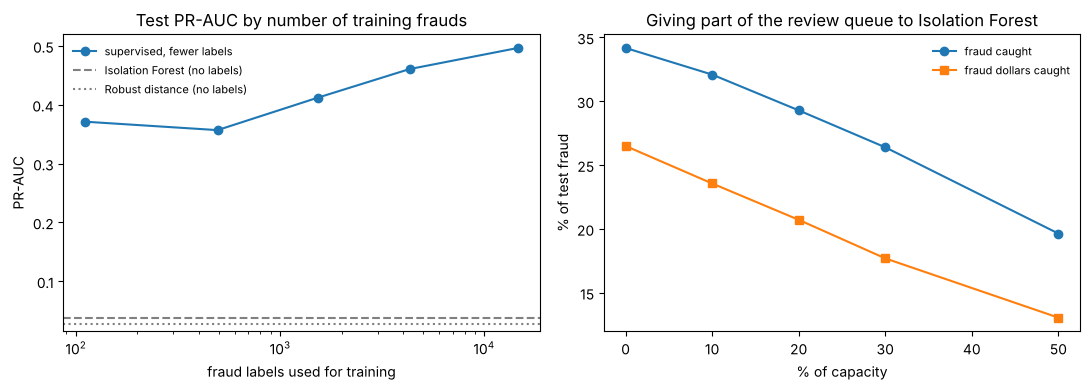

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(curve["training frauds"], curve["pr_auc"], marker="o", label="supervised, fewer labels")
for name, ls in (("Isolation Forest", "--"), ("Robust distance", ":")):
    ax.axhline(test.loc[name, "pr_auc"], ls=ls, color="grey", label=f"{name} (no labels)")
ax.set_xscale("log")
ax.set(title="Test PR-AUC by number of training frauds", xlabel="fraud labels used for training", ylabel="PR-AUC")
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
ax.plot(100 * blend["share of capacity to anomalies"], 100 * blend["recall"], marker="o", label="fraud caught")
ax.plot(100 * blend["share of capacity to anomalies"], 100 * blend["dollar_recall"], marker="s", label="fraud dollars caught")
ax.set(title=f"Giving part of the review queue to {best_detector}", xlabel="% of capacity", ylabel="% of test fraud")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
data.savefig(fig, "04_anomaly", SOURCE)

## Record and verdict

In [8]:
record = {
    "supervised_reference": supervised_name,
    "test": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in test.iterrows()},
    "missed_by_supervised": int(missed.sum()), "caught_in_detector_top": overlap,
    "best_detector": best_detector, "capacity_blend": blend.to_dict(orient="records"),
    "anomaly_profile": {f"{a} / {b}": {k: float(v) for k, v in r.items()} for (a, b), r in profile.iterrows()},
    "label_scarcity": curve.to_dict(orient="records"),
}
write_metrics("04_anomaly", record, SOURCE)

In [9]:
b = test.loc[best_detector]
base = float(y[te].mean())
chance = bool(test.loc[["Isolation Forest", "Robust distance"], "pr_auc"].max() < 1.5 * base)
pt = profile.loc[(best_detector, "top 1.5%")]
pr = profile.loc[(best_detector, "rest")]
s0 = blend.iloc[0]
best_blend = blend.loc[blend["recall"].idxmax()]
cross = curve[curve["pr_auc"] > b["pr_auc"]]
show_verdict(
    "Verdict: phase 4, anomaly detection",
    [
        (f"**Neither label-free detector does better than chance**: the better one, {best_detector}, has test PR-AUC "
         f"{b['pr_auc']:.3f} against a fraud rate of {base:.3f}, and finds {b['recall_at_capacity']:.1%} of fraud in its top "
         f"{cap:.1%}; the supervised model finds {test.loc['Supervised', 'recall_at_capacity']:.0%}." if chance else
         f"**Without labels, {best_detector} is the better detector**: test PR-AUC {b['pr_auc']:.3f} and "
         f"{b['recall_at_capacity']:.0%} of fraud in its top {cap:.1%}, against {test.loc['Supervised', 'pr_auc']:.3f} and "
         f"{test.loc['Supervised', 'recall_at_capacity']:.0%} for the supervised model."),
        (f"**Unusual is not the same as fraudulent.** {best_detector}'s most anomalous payments have a fraud rate of "
         f"{pt['fraud rate']:.2%} against {pr['fraud rate']:.2%} for the rest: they come from customers with a median of "
         f"{pt['median cust_prior_tx']:.0f} earlier payments (rest: {pr['median cust_prior_tx']:.0f}), heavy legitimate "
         "users whose counts are extreme. Fraud here does not stand out on any one dimension."
         if pt["fraud rate"] < pr["fraud rate"] else
         f"{best_detector}'s most anomalous payments have a fraud rate of {pt['fraud rate']:.2%} against "
         f"{pr['fraud rate']:.2%} for the rest (median {pt['median cust_prior_tx']:.0f} earlier payments by the customer, "
         f"rest {pr['median cust_prior_tx']:.0f})."),
        f"**Of {int(missed.sum())} test frauds outside the supervised queue**, "
        f"{overlap[best_detector]:.0%} are in {best_detector}'s top {cap:.1%}. Giving it part of the queue "
        + ("does not raise recall: no share tested catches more fraud than the supervised queue alone "
           f"({s0['recall']:.0%})." if best_blend["share of capacity to anomalies"] == 0 else
           f"raises recall to {best_blend['recall']:.0%} at {best_blend['share of capacity to anomalies']:.0%} of capacity "
           f"(from {s0['recall']:.0%})."),
        (f"**Labels win early**: with {int(cross.iloc[0]['training frauds'])} training frauds the supervised model already "
         f"beats the label-free detectors on PR-AUC." if len(cross) else
         "**The label-free detectors beat the supervised model at every label budget tested.**")
        + " The detectors' place is where labels do not exist yet: a new product or market, or as a drift alarm.",
    ],
    "Phase 5 turns the calibrated probabilities into approve / review / decline decisions by expected cost.",
)

### Verdict: phase 4, anomaly detection

1. **Neither label-free detector does better than chance**: the better one, Isolation Forest, has test PR-AUC 0.038 against a fraud rate of 0.035, and finds 0.5% of fraud in its top 1.5%; the supervised model finds 34%.
2. **Unusual is not the same as fraudulent.** Isolation Forest's most anomalous payments have a fraud rate of 1.15% against 3.51% for the rest: they come from customers with a median of 702 earlier payments (rest: 2), heavy legitimate users whose counts are extreme. Fraud here does not stand out on any one dimension.
3. **Of 2115 test frauds outside the supervised queue**, 0% are in Isolation Forest's top 1.5%. Giving it part of the queue does not raise recall: no share tested catches more fraud than the supervised queue alone (34%).
4. **Labels win early**: with 111 training frauds the supervised model already beats the label-free detectors on PR-AUC. The detectors' place is where labels do not exist yet: a new product or market, or as a drift alarm.

**Next:** Phase 5 turns the calibrated probabilities into approve / review / decline decisions by expected cost.